# 4. Analysis 2, the primary likely constraint

I then compared each priority station with the stations that have both a strong market and strong conditions. The deficit on a condition is how many points the station sits below that reference median. The largest deficit is the primary likely constraint. If the second deficit is within 10 points, I report a tie, because the evidence does not support a single label.

I do not use a first-match rule. A fixed order would have called a station a parking problem whenever the 2019 lot was full, even when the bus gap was larger.

I repeated the deficit against the station's own line. Where the label changes, I flag it and I do not treat it as a firm recommendation.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 140)
from scorecard.pipeline import load
table, recs, meta = load()

cols = ["station_name","line_name","primary_likely","constraint_share","is_tie","second_likely",
        "deficit_service","deficit_feeder","deficit_walk","deficit_parking","deficit_fare",
        "primary_vs_corridor","label_changes_with_corridor"]
focus = table[table.quadrant.eq("priority")]
print(focus[cols].sort_values("constraint_share", ascending=False).to_string(index=False))

         station_name      line_name primary_likely  constraint_share is_tie second_likely  deficit_service  deficit_feeder  deficit_walk  deficit_parking  deficit_fare primary_vs_corridor  label_changes_with_corridor
      Etobicoke North      Kitchener           walk          0.551437  False           NaN        26.428571       20.634921     57.857143              NaN     -7.142857                walk                        False
        Richmond Hill  Richmond Hill        service          0.524416  False           NaN        67.500000       35.873016     -9.285714        23.913043      1.428571             parking                         True
            Kitchener      Kitchener           fare          0.499397  False           NaN        36.428571       29.444444    -25.000000              NaN     65.714286                fare                        False
           Old Cummer  Richmond Hill        service          0.466411  False           NaN        67.500000       53.650794     

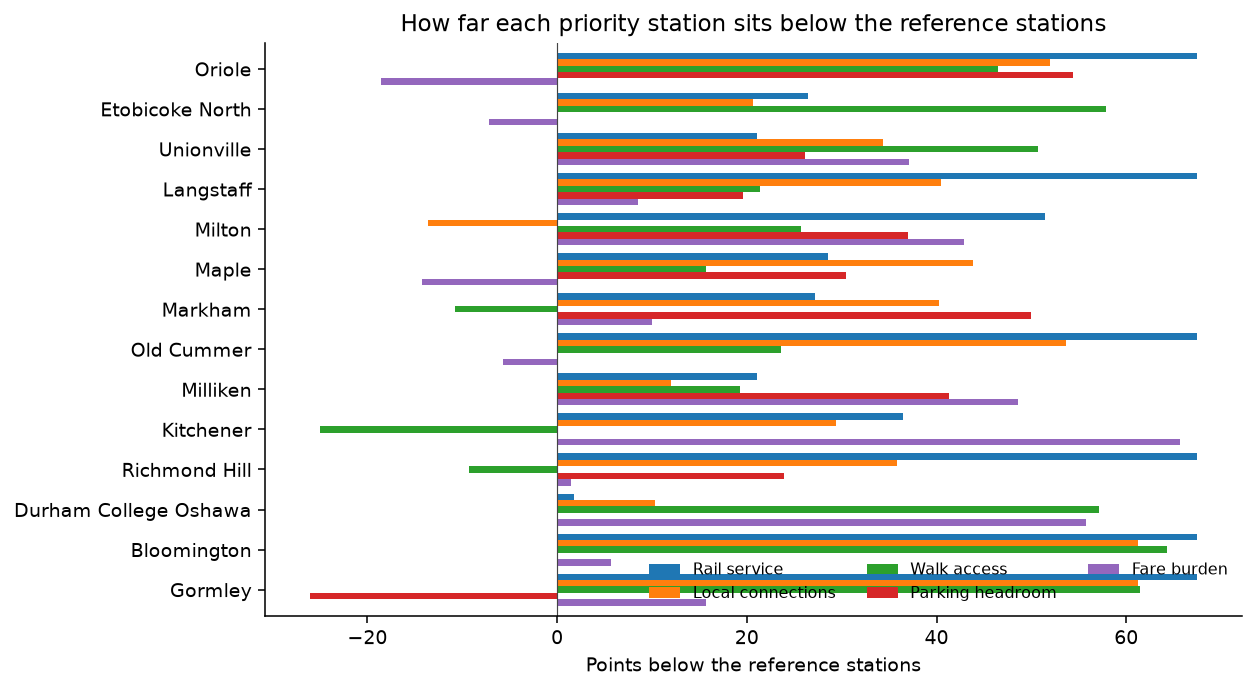

In [2]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "reports" / "figures" / "deficits.png")))